In [1]:
import pandas as pd

In [41]:
sample_df = pd.read_csv("../generated_data/timebin_identification/120days_window/120days_timebin_sample_df.csv")

C:\Users\yuyue\AppData\Local\Temp\ipykernel_24200\3704775865.py:1: DtypeWarning: Columns (16,17,18,19,20,29,31,43,44,50,51,73,75,77,78,79) have mixed types. Specify dtype option on import or set low_memory=False.
  sample_df = pd.read_csv("../generated_data/timebin_identification/120days_window/120days_timebin_sample_df.csv")


In [42]:
subset_sample_df = sample_df[['id', 'window_start', 'tweets_historical','created_at','profile_image_main_info']]

In [43]:
subset_sample_df

,id,window_start,tweets_historical,created_at,profile_image_main_info
0,12695752,2023-12-31 00:00:00+00:00,This should be the format of the second debate...,2024-04-26 15:02:35+00:00,### Analysis of the Profile Image\n\n#### 1. V...
1,12695752,2023-12-31 00:00:00+00:00,"@fredfred @midjourney """"Two nuns admit embezzl...",2024-04-25 22:52:34+00:00,### Analysis of the Profile Image\n\n#### 1. V...
2,12695752,2023-12-31 00:00:00+00:00,@Grey_Athena They think that if they make excu...,2024-04-25 13:40:56+00:00,### Analysis of the Profile Image\n\n#### 1. V...
3,12695752,2023-12-31 00:00:00+00:00,"""""I tremble to think of the number of TikToks ...",2024-04-22 20:43:45+00:00,### Analysis of the Profile Image\n\n#### 1. V...
4,12695752,2023-12-31 00:00:00+00:00,"Yet again, gonna have to pick a new start word...",2024-04-20 04:35:21+00:00,### Analysis of the Profile Image\n\n#### 1. V...
...,...,...,...,...,...
182250,1834689413168672768,2023-11-07 00:00:00+00:00,NaN,NaN,The image is an anime-style illustration of a ...
182251,1834689413168672768,2024-06-26 00:00:00+00:00,People are increasingly looking to financial s...,2024-09-28 11:15:18+00:00,The image is an anime-style illustration of a ...
182252,1834689413168672768,2024-06-26 00:00:00+00:00,"Courtside confidence is contagious, teams that...",2024-09-18 05:49:56+00:00,The image is an anime-style illustration of a ...
182253,1839135745908305920,2023-11-23 00:00:00+00:00,NaN,NaN,**1. Visible Physical Characteristics:**\n\n* ...


In [44]:
import pandas as pd
import os
import numpy as np

# Election date
election_date = pd.to_datetime("2024-11-05")

# Remove timezone function
def make_naive(dt):
    if pd.isna(dt):
        return dt
    if dt.tzinfo is not None:
        return dt.tz_convert(None) if hasattr(dt, 'tz_convert') else dt.replace(tzinfo=None)
    return dt

# Clean tweets file
def process_file(file_path, output_path):
    print(f"Processing {file_path}...")

    df = pd.read_csv(file_path)
    df['created_at'] = pd.to_datetime(df['created_at']).apply(make_naive)
    mask = df['created_at'].notna()
    df.loc[mask, 'days_to_election'] = (election_date - df.loc[mask, 'created_at']).dt.days.astype(int)
    df.loc[~mask, 'days_to_election'] = np.nan

    df['tweets_struct'] = df.apply(
        lambda row: {
            'text': row['tweets_historical'],
            'created_at': row['created_at']
        }if pd.notna(row['created_at']) else None, 
        axis=1
    )

    window_profiles = (
        df.groupby(['id', 'window_start', 'window_end'])
        .agg({
            'name': 'first',
            'username': 'first',
            'description': 'first',
            'location': 'first',
            'profile_image_main_info': 'first',
            'public_metrics.followers_count': 'first',
            'is_empty_window': 'first',
            'clean...pool': 'first',  
            'days_to_election': 'min',
            'tweets_struct': lambda x: [item for item in x if item is not None],
        })
        .reset_index()
    )
    def add_window_header(tweets_list, days_to_election):
        if pd.notna(days_to_election):
            header = f"{int(days_to_election)} days to election"
            return [header] + tweets_list
        else:
            return tweets_list
    
    window_profiles['tweets_struct'] = window_profiles.apply(
        lambda row: add_window_header(row['tweets_struct'], row['days_to_election']),
        axis=1
    )

    window_profiles.to_csv(output_path, index=False)
    print(f"Saved cleaned file to {output_path}")


input_file = "../generated_data/timebin_identification/120days_window/120days_timebin_sample_df.csv"
output_file = "../generated_data/timebin_identification/120days_window/cleaned_120days_timebin_sample_df.csv"

process_file(input_file, output_file)


Processing ../generated_data/timebin_identification/120days_window/120days_timebin_sample_df.csv...


C:\Users\yuyue\AppData\Local\Temp\ipykernel_24200\3775739847.py:20: DtypeWarning: Columns (16,17,18,19,20,29,31,43,44,50,51,73,75,77,78,79) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Saved cleaned file to ../generated_data/timebin_identification/120days_window/cleaned_120days_timebin_sample_df.csv


In [45]:
final_df = pd.read_csv("../generated_data/timebin_identification/120days_window/cleaned_120days_timebin_sample_df.csv")
final_df

,id,window_start,window_end,name,username,description,location,profile_image_main_info,public_metrics.followers_count,is_empty_window,clean...pool,days_to_election,tweets_struct
0,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,### Analysis of the Profile Image\n\n#### 1. V...,1249,False,trad,192.0,"['192 days to election', {'text': 'This should..."
1,12695752,2024-05-05 00:00:00+00:00,2024-09-01 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,### Analysis of the Profile Image\n\n#### 1. V...,1249,False,trad,65.0,"['65 days to election', {'text': ""It's only we..."
2,14728999,2023-11-13 00:00:00+00:00,2024-03-11 00:00:00+00:00,Mark Groubert,lordbuckly,Writer LA Weekly/Editor National Lampoon mag/P...,"Hollywood, CA.",### **1. Visible Physical Characteristics:**\n...,14217,True,trad,NaN,[]
3,14728999,2024-03-19 00:00:00+00:00,2024-07-16 00:00:00+00:00,Mark Groubert,lordbuckly,Writer LA Weekly/Editor National Lampoon mag/P...,"Hollywood, CA.",### **1. Visible Physical Characteristics:**\n...,14217,False,trad,112.0,"['112 days to election', {'text': ""Trump shoot..."
4,15253258,2023-12-23 00:00:00+00:00,2024-04-20 00:00:00+00:00,Thorsten Linz,tvonlinz,"#InnovareAI CEO, #AI & #Automation expert, #Si...",San Francisco,### 1. List of visible physical characteristic...,2135,True,protectionism,NaN,[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,1825634298080141313,2024-05-16 00:00:00+00:00,2024-09-12 00:00:00+00:00,Jahova,YahwehLordzzz,Comedy Show,Bedroom,Profile image description is not available for...,26,False,guns,57.0,"['57 days to election', {'text': 'It’s called ..."
311,1834689413168672768,2023-11-07 00:00:00+00:00,2024-03-05 00:00:00+00:00,Tiffany Scott,TiffanySco83644,Actively seeking passive income | Proud TIA Pr...,Torrance,The image is an anime-style illustration of a ...,0,True,immigration,NaN,[]
312,1834689413168672768,2024-06-26 00:00:00+00:00,2024-10-23 00:00:00+00:00,Tiffany Scott,TiffanySco83644,Actively seeking passive income | Proud TIA Pr...,Torrance,The image is an anime-style illustration of a ...,0,False,immigration,37.0,"['37 days to election', {'text': ""People are i..."
313,1839135745908305920,2023-11-23 00:00:00+00:00,2024-03-21 00:00:00+00:00,Michael Holloway,highway_vessel,Foodie,USA,**1. Visible Physical Characteristics:**\n\n* ...,0,True,democracy,NaN,[]


In [46]:
import os
import re
import json
import time
import pandas as pd
import requests
import numpy as np
import hashlib

# ----------------------------
# 1. Endpoint & authentication
# ----------------------------
endpoint_base = "https://aipolling.services.ai.azure.com/models"
api_version = "2024-05-01-preview"
url = f"{endpoint_base}/chat/completions?api-version={api_version}"

api_key = os.getenv("AZURE_API_KEY")
if not api_key:
    raise ValueError("AZURE_API_KEY environment variable is not set")

# ----------------------------
# 2. Prompt Template
# ----------------------------
prompt_template = """
A social media account has the following username, name, description:
- Name: {name}  
- Username: {username}  
- Description: {description}  
A structured description of a profile image is the following:
- Profile Image Description: {profile_image_description}
Furthermore, they self-report their location in their bio as: {location}  
The amount of followers they have is: {followers}  
They have written the following tweet(s): {tweets}  

I will show you a number of categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
Please select, for each title, the most likely category to which this user belongs to.
Please think about this step by step.

In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.

For each selected symbol / category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, every single element of the user data was useful in the selection) to 100 (fully speculative, there is no information related to this title in the user data).
Speculation levels should be a direct measure of the amount of useful information available in the user data.
Speculation levels pertain only to the information available in the user data -- namely the username, name, description, location, profile picture and tweets from this user -- and should not be affected by additional information available to you from any other source.

To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The user data provides clear and direct information relevant to the title. (e.g., explicit mention in the profile or tweets)
21-40 (Moderate-low speculation): The user data provides indirect but strong indicators relevant to the title.
41-60 (Moderate speculation): The user data provides some hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The user data provides limited and weak indicators relevant to the title.
81-100 (High speculation): The user data provides no or almost no information relevant to the title.

For each selected category, please explain at length what features of the data contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

**title: AGE**
**explanation: ...**
**symbol: A1)**
**category: 18-25**
**speculation: 90**

YOU MUST GIVE AN ANSWER FOR EVERY TITLE !

Below is the list of categories to which this user may belong to:
{topic_question}

- **OPINION ON WHICH SIDE HAS MORE VALID REASONS IN THE ISRAEL-HAMAS WAR:** 
    Choose one: [
    IsA1) Israel has much more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA2) Israel has somewhat more valid reasons for waging war against Hamas than Hamas has for waging war against Israel, 
    IsA3) Israel's reasons for waging war against Hamas and Hamas' reasons for waging war against Israel are equally valid, 
    IsA4) Hamas has somewhat more valid reasons for waging war against Israel than Israel has for waging war against Hamas, 
    IsA5) Hamas has much more valid reasons for waging war against Israel than Israel has for waging war against Hamas]

"""
# ----------------------------
# 3. Topic Question Library
# ----------------------------
topic_questions = {
    "economy": """- **OPINION ON EXPANDING THE CHILD TAX CREDIT : ** 
    Choose one: [
    FeE1) The reason to expand the child tax credit is to incentivise couples to have more children and combat low fertility rates,
    FeE2) The reason to expand the child tax credit is to provide financial aid to working class and low-income parents,
    FeE3) There is no valid reason to expand the child tax credit, as it should not be expanded]""",
    
    "immigration": """- **OPINION ON WHAT SHOULD BE DONE WITH ILLEGAL IMMIGRANTS : ** 
    Choose one: [
    ImD1) Illegal immigrants should be allowed to become citizens, provided they meet certain requirements,
    ImD2) Illegal immigrants should be allowed to become permanent legal residents, but not citizens,
    ImD3) Illegal immigrants should be identified and deported]""",

    "protectionism": """- **OPINION ON THE STATEMENT << OUTSOURCING JOBS TO OTHER COUNTRIES HARMS US WORKERS >> : ** 
    Choose one: [
    PrB1) Strongly agree with the statement << Outsourcing jobs to other countries harms US workers >>, 
    PrB2) Somewhat agree with the statement << Outsourcing jobs to other countries harms US workers >>,
    PrB3) Somewhat disagree with the statement << Outsourcing jobs to other countries harms US workers >>,
    PrB4) Strongly disagree with the statement << Outsourcing jobs to other countries harms US workers >>]""",

    "crime": """- **OPINION ON FUNDING OF POLICE DEPARTMENTS : ** 
    Choose one: [
    CrC1) Funding of police departments in my community should be increased a lot,
    CrC2) Funding of police departments in my community should be increased a little,
    CrC3) Funding of police departments in my community should remain the same as it is,
    CrC4) Funding of police departments in my community should be reduced a little,
    CrC5) Funding of police departments in my community should be reduced a lot]""",

    "trad": """- **OPINION ON WHETHER DIVORCE IN THE USA SHOULD BE EASIER OR MORE DIFFICULT TO OBTAIN THAN IT IS : ** 
    Choose one: [
    SoA1) Obtaining a divorce should be easier than it is,
    SoA2) Obtaining a divorce should be more difficult than it is,
    SoA3) Obtaining a divorce is the right level of difficulty as it is]""",

    "woke": """- **OPINION ON THE FOLLOWING STATEMENT << HOMOSEXUAL COUPLES SHOULD HAVE THE RIGHT TO MARRY ONE ANOTHER >> : ** 
    Choose one: [
    SoD1) Strongly agree with the statement << Homosexual couples should have the right to marry one another >>,
    SoD2) Somewhat agree with the statement << Homosexual couples should have the right to marry one another >>,
    SoD3) Somewhat disagree with the statement << Homosexual couples should have the right to marry one another >>,
    SoD4) Strongly disagree with the statement << Homosexual couples should have the right to marry one another >>]""",

    "health": """- **OPINION ON THE FOLLOWING STATEMENT << OVERALL, VACCINATIONS DO MORE HARM THAN GOOD >> : ** 
    Choose one: [
    HeC1) Strongly agree with the statement << Overall, vaccinations do more harm than good >>,
    HeC2) Somewhat agree with the statement << Overall, vaccinations do more harm than good >>,
    HeC3) Somewhat disagree with the statement << Overall, vaccinations do more harm than good >>,
    HeC4) Strongly disagree with the statement << Overall, vaccinations do more harm than good >>]""",

    "drugs": """- **OPINION ON MARIJUANA LEGALISATION : ** 
    Choose one: [
    DrA1) Marijuana should be legal for medical and recriational use,
    DrA2) Marijuana should be legal for medical use only,
    DrA3) Marijuana should not be legal]""",    

    "guns": """- **OPINION ON THE STATEMENT << A PERSON SHOULD REQUIRE A POLICE PERMIT BEFORE HE OR SHE COULD BUY A GUN >> : ** 
    Choose one: [
    GuA1) Strongly agree with the statement << a person should require a police permit before he or she could buy a gun >>,
    GuA2) Somewhat agree with the statement << a person should require a police permit before he or she could buy a gun >>,
    GuA3) Somewhat disagree with the statement << a person should require a police permit before he or she could buy a gun >>,
    GuA4) Strongly disagree with the statement << a person should require a police permit before he or she could buy a gun >>]""",    

    "race": """- **OPINION ON THE STATEMENT << A PERSON SHOULD REQUIRE A POLICE PERMIT BEFORE HE OR SHE COULD BUY A GUN >> : ** 
    Choose one: [
    GuA1) Strongly agree with the statement << a person should require a police permit before he or she could buy a gun >>,
    GuA2) Somewhat agree with the statement << a person should require a police permit before he or she could buy a gun >>,
    GuA3) Somewhat disagree with the statement << a person should require a police permit before he or she could buy a gun >>,
    GuA4) Strongly disagree with the statement << a person should require a police permit before he or she could buy a gun >>]""", 

    "frees speech": """- **OPINION ON THE STATEMENT << BOOKS EXPRESSING HARMFUL IDEAS SHOULD BE REMOVED FROM LIBRARIES IN MY COMMUNITY >> : ** 
    Choose one: [
    FrA1) Strongly agree with the statment << Books expressing harmful ideas should be removed from libraries in my community >>,
    FrA2) Somewhat agree with the statment << Books expressing harmful ideas should be removed from libraries in my community >>,
    FrA3) Somewhat disagree with the statement << Books expressing harmful ideas should be removed from libraries in my community >>,
    FrA4) Strongly disagree with the statment << Books expressing harmful ideas should be removed from libraries in my community >>]""", 

    "foreign policy": """- **OPINION ON WHICH SIDE HAS MORE VALID REASONS IN THE ISRAEL-HAMAS WAR : ** 
    Choose one: [
    IsA1) Israel has much more valid reasons for waging war against Hamas than Hamas has for waging war against Israel,
    IsA2) Israel has somewhat more valid reasons for waging war against Hamas than Hamas has for waging war against Israel,
    IsA3) Israel's reasons for waging war against Hamas and Hamas' reasons for waging war against Israel are equally valid,
    IsA4) Hamas has somewhat more valid reasons for waging war against Israel than Israel has for waging war against Hamas,
    IsA5) Hamas has much more valid reasons for waging war against Israel than Israel has for waging war against Hamas]""",    

    "radical": """- **OPINION ON THE EXTENT TO WHICH THIS INDIVIDUAL FEELS IT IS JUSTIFIED FOR PEOPLE TO USE VIOLENCE TO PURSUE THEIR POLITICAL GOALS IN THIS COUNTRY : ** 
    Choose one: [
    FrB1) It is justified a great deal for people to use violence to pursue their political goals in this country,
    FrB2) It is justified a lot for people to use violence to pursue their political goals in this country,
    FrB3) It is justified to a moderate amount for people to use violence to pursue their political goals in this country,
    FrB4) It is justified a little for people to use violence to pursue their political goals in this country,
    FrB5) It is not at all justified for people to use violence to pursue their political goals in this country]""", 

    "democracy": """- **OPINION ON JANUARY 6th STORMING OF THE US CAPITOL:** 
    Choose one: [
    DeB1) The storming of the capitol on January 6, 2021 was an insurrection and a threat to democracy,
    DeB2) The storming of the capitol on January 6, 2021 was a political protest protected under the first amendment,
    DeB3) The storming of the capitol on January 6, 2021 was an unfortunate event, but in the past, so no need to worry about it anymore]""", 

    "media": """- **BELIEF ON LIKELIHOOD THAT SOCIAL MEDIA COMPANIES ARE INTENTIONALLY CENSORING POLITICAL VIEWS THEY OBJECT TO : ** 
    Choose one: [
    DeC1) Very likely that social media companies are intentionally censoring political views they object to, 
    DeC2) Somewhat likely that social media companies are intentionally censoring political views they object to,
    DeC3) Somewhat unlikely that social media companies are intentionally censoring political views they object to,
    DeC4) Very unlikely that social media companies are intentionally censoring political views they object to]""",  

    "climate": """- **OPINION ON THE STATEMENT << CLIMATE CHANGE IS A MAJOR THREAT TO THE UNITED STATES >> : ** 
    Choose one: [
    ClG1) Strongly agree with the statement << Climate change is a major threat to the United States >>,
    ClG2) Somewhat agree with the statement << Climate change is a major threat to the United States >>,
    ClG3) Somewhat disagree with the statement << Climate change is a major threat to the United States >>,
    ClG4) Strongly disagree with the statement << Climate change is a major threat to the United States >>]""",  

    "discourse": """- **OPINION ON WHETHER THE TONE OF POLITICAL DISCOURSE IN THE U.S. HAS BECOME MORE FACT-BASED : ** 
    Choose one: [
    DiB1) The tone of political discourse in the U.S. has become more fact-based, 
    DiA2)  The tone of political discourse in the U.S. has become less fact-based, 
    DiA3) The tone of political discourse in the U.S. has not changed much]""",  
}

# ----------------------------
# 4. Belief Parsing Function (Generic Output Columns)
# ----------------------------
def parse_belief_response(response):
    parsed = {
        "Belief_inpool_Category": None,
        "Belief_inpool_Explanation": None,
        "Belief_inpool_Speculation": None,
        "Belief_outpool_Category": None,
        "Belief_outpool_Explanation": None,
        "Belief_outpool_Speculation": None
    }

    pattern = (
        r"\*\*title:?\s*(.*?)\*\*"
        r"\s*\*\*explanation:?\**\s*(.*?)"
        r"\s*\*\*symbol:?\**\s*(.*?)"
        r"\s*\*\*category:?\**\s*(.*?)"
        r"\s*\*\*speculation:?\**\s*(\d+)"
    )

    matches = re.findall(pattern, str(response), re.DOTALL)

    # We store first non-Israel/Hamas result as in-pool
    inpool_filled = False
    for title, explanation, symbol, category, speculation in matches:
        title_clean = title.strip().lower()
        if ("israel" in title_clean) or ("hamas" in title_clean):
            parsed["Belief_outpool_Category"] = category.strip()
            parsed["Belief_outpool_Explanation"] = explanation.strip()
            parsed["Belief_outpool_Speculation"] = speculation.strip()
        else:
            if not inpool_filled:  # Only take the first non-Israel/Hamas title as in-pool
                parsed["Belief_inpool_Category"] = category.strip()
                parsed["Belief_inpool_Explanation"] = explanation.strip()
                parsed["Belief_inpool_Speculation"] = speculation.strip()
                inpool_filled = True

    return parsed

# ----------------------------
# 5. Model Inference
# ----------------------------

def infer_beliefs(row, model_name, topic_question):
    prompt = prompt_template.format(
        name=row['name'],
        username=row['username'],
        description=row['description'],
        location=row['location'],
        followers=row['public_metrics.followers_count'],
        tweets=row['tweets_struct'],
        profile_image_description=row['profile_image_main_info'],
        topic_question=topic_question
    )

    # print("\n=== PROMPT PREVIEW ===")
    # print(prompt)
    # print("======================\n")

    messages = [
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": prompt}
    ]

    body = {"model": model_name, "max_tokens": 4096, "messages": messages}
    headers = {"Content-Type": "application/json", "api-key": api_key}

    response = requests.post(url, headers=headers, data=json.dumps(body))
    response.raise_for_status()
    belief_text = response.json()["choices"][0]["message"]["content"]
    return belief_text


def generate_unique_id(row, topic_column):
    """Hash the tweet text + topic to get a unique ID"""
    text_to_hash = str(row["tweets_struct"]) + str(row[topic_column])
    return hashlib.md5(text_to_hash.encode("utf-8")).hexdigest()


input_file = "../generated_data/timebin_identification/120days_window/cleaned_120days_timebin_sample_df.csv"
output_file = "../generated_data/timebin_identification/120days_window/120days_alltopics_beliefs_scored.csv"
topic_column = "clean...pool"  
os.makedirs(os.path.dirname(output_file), exist_ok=True)

df = pd.read_csv(input_file)

# Load already processed results if resuming
if os.path.exists(output_file):
    processed_df = pd.read_csv(output_file)
    processed_ids = set(processed_df["unique_id"]) if "unique_id" in processed_df else set()
    print(f"Resuming: {len(processed_ids)} rows already processed.")
    all_results = processed_df.to_dict("records")
else:
    processed_ids = set()
    all_results = []

models = ["gpt-oss-120b"]

for model_name in models:
    for index, row in df.iterrows():
        unique_id = generate_unique_id(row, topic_column)
        if unique_id in processed_ids:
            continue  
        if row.get("is_empty_window", False):
            combined_row = row.to_dict()
            combined_row.update({
                "Model": model_name,
                "Belief_Raw": np.nan,
                "Topic": row[topic_column],
                "unique_id": unique_id,
                "Belief_inpool_Category": np.nan,
                "Belief_inpool_Text": np.nan,
                "Belief_outpool_Category": np.nan,
                "Belief_outpool_Explanation": np.nan,
                "Belief_outpool_Speculation": np.nan,
                "Profile_Image_Description": "No profile image available."
            })
            all_results.append(combined_row)
            continue  # skip API call
        topic_key = row["clean...pool"]
        topic_question = topic_questions.get(topic_key)
        if not topic_question:
            print(f"Skipping row {index} (no topic question for {topic_key})")
            continue

        try:
            belief_text = infer_beliefs(row, model_name, topic_question)
            parsed_result = parse_belief_response(belief_text)

            combined_row = row.to_dict()
            combined_row.update({
                "Model": model_name,
                "Belief_Raw": belief_text,
                "Topic": topic_key,
                "unique_id": unique_id
            })
            combined_row.update(parsed_result)
            all_results.append(combined_row)

            # Save progress every 20 rows 
            if len(all_results) % 20 == 0:
                pd.DataFrame(all_results).to_csv(output_file, index=False, encoding="utf-8-sig")
                print(f"Progress saved: {len(all_results)} rows processed so far.")

            time.sleep(1)  # avoid rate limiting

        except Exception as e:
            print(f"Error processing row {index} for model {model_name}: {e}")

# ----------------------------
# 5. Save final results
# ----------------------------
pd.DataFrame(all_results).to_csv(output_file, index=False, encoding="utf-8-sig")
print(f"Done. Combined output saved to: {output_file}")


Error processing row 5 for model gpt-oss-120b: 400 Client Error: Bad Request for url: https://aipolling.services.ai.azure.com/models/chat/completions?api-version=2024-05-01-preview
Error processing row 24 for model gpt-oss-120b: 400 Client Error: Bad Request for url: https://aipolling.services.ai.azure.com/models/chat/completions?api-version=2024-05-01-preview
Error processing row 26 for model gpt-oss-120b: 400 Client Error: Bad Request for url: https://aipolling.services.ai.azure.com/models/chat/completions?api-version=2024-05-01-preview
Error processing row 29 for model gpt-oss-120b: 400 Client Error: Bad Request for url: https://aipolling.services.ai.azure.com/models/chat/completions?api-version=2024-05-01-preview
Progress saved: 40 rows processed so far.
Error processing row 63 for model gpt-oss-120b: 400 Client Error: Bad Request for url: https://aipolling.services.ai.azure.com/models/chat/completions?api-version=2024-05-01-preview
Progress saved: 60 rows processed so far.
Error p

In [47]:
test_df = pd.read_csv("../generated_data/timebin_identification/120days_window/120days_alltopics_beliefs_scored.csv")
test_df

,id,window_start,window_end,name,username,description,location,profile_image_main_info,public_metrics.followers_count,is_empty_window,...,Topic,unique_id,Belief_inpool_Category,Belief_inpool_Explanation,Belief_inpool_Speculation,Belief_outpool_Category,Belief_outpool_Explanation,Belief_outpool_Speculation,Belief_inpool_Text,Profile_Image_Description
0,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,### Analysis of the Profile Image\n\n#### 1. V...,1249,False,...,trad,5a14d35506734cd6e05d83f86346015b,Obtaining a divorce is the right level of diff...,"The user’s profile (name, username, descriptio...",88.0,Israel's reasons for waging war against Hamas ...,The user’s tweets are heavily focused on U.S. ...,86.0,NaN,NaN
1,12695752,2024-05-05 00:00:00+00:00,2024-09-01 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,### Analysis of the Profile Image\n\n#### 1. V...,1249,False,...,trad,48fdea4da121439af9c3f288331a45b1,Obtaining a divorce should be easier than it is,The user’s profile and tweet history contain n...,82.0,Israel's reasons for waging war against Hamas ...,The tweet archive does not contain any explici...,88.0,NaN,NaN
2,14728999,2023-11-13 00:00:00+00:00,2024-03-11 00:00:00+00:00,Mark Groubert,lordbuckly,Writer LA Weekly/Editor National Lampoon mag/P...,"Hollywood, CA.",### **1. Visible Physical Characteristics:**\n...,14217,True,...,trad,cae74b5d032090f917acd83902b3db98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image available.
3,14728999,2024-03-19 00:00:00+00:00,2024-07-16 00:00:00+00:00,Mark Groubert,lordbuckly,Writer LA Weekly/Editor National Lampoon mag/P...,"Hollywood, CA.",### **1. Visible Physical Characteristics:**\n...,14217,False,...,trad,aa178560007056d064f00a2f47b72fad,Obtaining a divorce should be more difficult t...,The user’s profile and tweet history contain n...,85.0,Israel has much more valid reasons for waging ...,The user never states a position on the Israel...,60.0,NaN,NaN
4,15253258,2023-12-23 00:00:00+00:00,2024-04-20 00:00:00+00:00,Thorsten Linz,tvonlinz,"#InnovareAI CEO, #AI & #Automation expert, #Si...",San Francisco,### 1. List of visible physical characteristic...,2135,True,...,protectionism,8b84622ca3a0df663a357d09344a8aba,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image available.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
280,1825634298080141313,2024-05-16 00:00:00+00:00,2024-09-12 00:00:00+00:00,Jahova,YahwehLordzzz,Comedy Show,Bedroom,Profile image description is not available for...,26,False,...,guns,5ca793f4cef9579635074d0253000ccb,Strongly disagree with the statement << a pers...,The user’s profile and tweet history contain n...,82.0,Israel's reasons for waging war against Hamas ...,"The user’s content does not mention Israel, Ha...",94.0,NaN,NaN
281,1834689413168672768,2023-11-07 00:00:00+00:00,2024-03-05 00:00:00+00:00,Tiffany Scott,TiffanySco83644,Actively seeking passive income | Proud TIA Pr...,Torrance,The image is an anime-style illustration of a ...,0,True,...,immigration,5add7262259ff592e21e1e32c2c20651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image available.
282,1834689413168672768,2024-06-26 00:00:00+00:00,2024-10-23 00:00:00+00:00,Tiffany Scott,TiffanySco83644,Actively seeking passive income | Proud TIA Pr...,Torrance,The image is an anime-style illustration of a ...,0,False,...,immigration,b4aee0ea3c16872b18f7e2a2ad2dc5be,Illegal immigrants should be allowed to become...,The user’s profile and tweets provide no expli...,85.0,Israel's reasons for waging war against Hamas ...,The user’s content contains no direct commenta...,88.0,NaN,NaN
283,1839135745908305920,2023-11-23 00:00:00+00:00,2024-03-21 00:00:00+00:00,Michael Holloway,highway_vessel,Foodie,USA,**1. Visible Physical Characteristics:**\n\n* ...,0,True,...,democracy,3a0c1b6d98b7f4e1e9ae391188729d07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image availab

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../generated_data/timebin_identification/120days_window/120days_alltopics_beliefs_scored.csv")
df

,id,window_start,window_end,name,username,description,location,profile_image_main_info,public_metrics.followers_count,is_empty_window,...,Topic,unique_id,Belief_inpool_Category,Belief_inpool_Explanation,Belief_inpool_Speculation,Belief_outpool_Category,Belief_outpool_Explanation,Belief_outpool_Speculation,Belief_inpool_Text,Profile_Image_Description
0,12695752,2023-12-31 00:00:00+00:00,2024-04-28 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,### Analysis of the Profile Image\n\n#### 1. V...,1249,False,...,trad,5a14d35506734cd6e05d83f86346015b,Obtaining a divorce is the right level of diff...,"The user’s profile (name, username, descriptio...",88.0,Israel's reasons for waging war against Hamas ...,The user’s tweets are heavily focused on U.S. ...,86.0,NaN,NaN
1,12695752,2024-05-05 00:00:00+00:00,2024-09-01 00:00:00+00:00,Dan Curtis Johnson,dcurtisj,Dantooine. They're on Dantooine.,Silicon Valley,### Analysis of the Profile Image\n\n#### 1. V...,1249,False,...,trad,48fdea4da121439af9c3f288331a45b1,Obtaining a divorce should be easier than it is,The user’s profile and tweet history contain n...,82.0,Israel's reasons for waging war against Hamas ...,The tweet archive does not contain any explici...,88.0,NaN,NaN
2,14728999,2023-11-13 00:00:00+00:00,2024-03-11 00:00:00+00:00,Mark Groubert,lordbuckly,Writer LA Weekly/Editor National Lampoon mag/P...,"Hollywood, CA.",### **1. Visible Physical Characteristics:**\n...,14217,True,...,trad,cae74b5d032090f917acd83902b3db98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image available.
3,14728999,2024-03-19 00:00:00+00:00,2024-07-16 00:00:00+00:00,Mark Groubert,lordbuckly,Writer LA Weekly/Editor National Lampoon mag/P...,"Hollywood, CA.",### **1. Visible Physical Characteristics:**\n...,14217,False,...,trad,aa178560007056d064f00a2f47b72fad,Obtaining a divorce should be more difficult t...,The user’s profile and tweet history contain n...,85.0,Israel has much more valid reasons for waging ...,The user never states a position on the Israel...,60.0,NaN,NaN
4,15253258,2023-12-23 00:00:00+00:00,2024-04-20 00:00:00+00:00,Thorsten Linz,tvonlinz,"#InnovareAI CEO, #AI & #Automation expert, #Si...",San Francisco,### 1. List of visible physical characteristic...,2135,True,...,protectionism,8b84622ca3a0df663a357d09344a8aba,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image available.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
280,1825634298080141313,2024-05-16 00:00:00+00:00,2024-09-12 00:00:00+00:00,Jahova,YahwehLordzzz,Comedy Show,Bedroom,Profile image description is not available for...,26,False,...,guns,5ca793f4cef9579635074d0253000ccb,Strongly disagree with the statement << a pers...,The user’s profile and tweet history contain n...,82.0,Israel's reasons for waging war against Hamas ...,"The user’s content does not mention Israel, Ha...",94.0,NaN,NaN
281,1834689413168672768,2023-11-07 00:00:00+00:00,2024-03-05 00:00:00+00:00,Tiffany Scott,TiffanySco83644,Actively seeking passive income | Proud TIA Pr...,Torrance,The image is an anime-style illustration of a ...,0,True,...,immigration,5add7262259ff592e21e1e32c2c20651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image available.
282,1834689413168672768,2024-06-26 00:00:00+00:00,2024-10-23 00:00:00+00:00,Tiffany Scott,TiffanySco83644,Actively seeking passive income | Proud TIA Pr...,Torrance,The image is an anime-style illustration of a ...,0,False,...,immigration,b4aee0ea3c16872b18f7e2a2ad2dc5be,Illegal immigrants should be allowed to become...,The user’s profile and tweets provide no expli...,85.0,Israel's reasons for waging war against Hamas ...,The user’s content contains no direct commenta...,88.0,NaN,NaN
283,1839135745908305920,2023-11-23 00:00:00+00:00,2024-03-21 00:00:00+00:00,Michael Holloway,highway_vessel,Foodie,USA,**1. Visible Physical Characteristics:**\n\n* ...,0,True,...,democracy,3a0c1b6d98b7f4e1e9ae391188729d07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No profile image availab

In [11]:
import pandas as pd
import glob
import os

window_folders = {
    "7d": "../generated_data/timebin_identification/7days_window/7days_alltopics_beliefs_scored.csv",
    "14d": "../generated_data/timebin_identification/14days_window/14days_alltopics_beliefs_scored.csv",
    "30d":  "../generated_data/timebin_identification/30days_window/30days_alltopics_beliefs_scored.csv",
    "60d":  "../generated_data/timebin_identification/60days_window/60days_alltopics_beliefs_scored.csv",
    "90d":  "../generated_data/timebin_identification/90days_window/90days_alltopics_beliefs_scored.csv",
    "120d":  "../generated_data/timebin_identification/120days_window/120days_alltopics_beliefs_scored.csv",
}

results = []

for window_length, path_pattern in window_folders.items():
    files = glob.glob(path_pattern)
    dfs = [pd.read_csv(f) for f in files]
    df = pd.concat(dfs, ignore_index=True)
    
    # Compute per-topic mean speculation
    topic_means = df.groupby("Topic").agg({
        "Belief_inpool_Speculation": "mean",
        "Belief_outpool_Speculation": "mean"
    }).reset_index()

    # Compute hierarchical mean 
    inpool_mean = topic_means["Belief_inpool_Speculation"].mean()
    outpool_mean = topic_means["Belief_outpool_Speculation"].mean()

    # Compute hierarchical SD
    inpool_sd = topic_means["Belief_inpool_Speculation"].std()
    outpool_sd = topic_means["Belief_outpool_Speculation"].std()

    results.append({
        "window_length": window_length,
        "inpool_mean": inpool_mean,
        "inpool_sd": inpool_sd,
        "outpool_mean": outpool_mean,
        "outpool_sd": outpool_sd
    })

summary_df = pd.DataFrame(results)

summary_df


,window_length,inpool_mean,inpool_sd,outpool_mean,outpool_sd
0,7d,57.925253,11.393363,69.246209,10.855831
1,14d,57.665826,13.253226,69.576529,12.419073
2,30d,56.673568,12.079041,68.194821,13.309525
3,60d,56.579550,13.253388,68.254020,11.818031
4,90d,54.548563,15.248475,66.675800,15.239200
5,120d,56.723355,11.827631,68.430113,12.610522


C:\Users\yuyue\AppData\Local\Temp\ipykernel_32812\2779034965.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["window_start"].dt.to_period("M").dt.to_timestamp()
C:\Users\yuyue\AppData\Local\Temp\ipykernel_32812\2779034965.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap("tab20", num_topics).colors


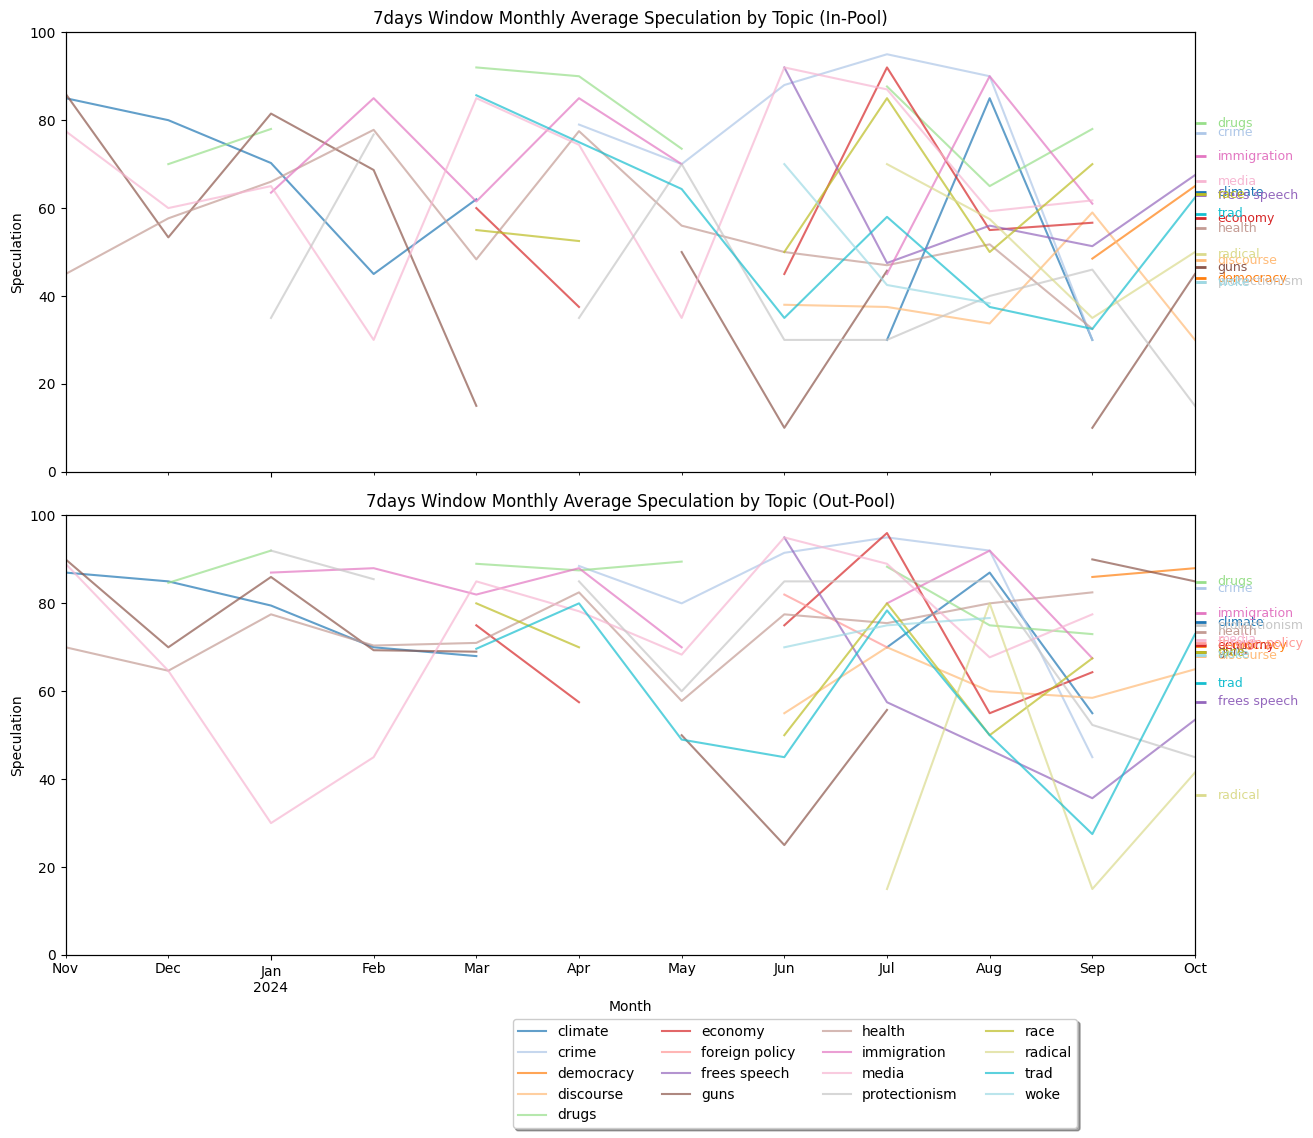

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

df = pd.read_csv("../generated_data/timebin_identification/7days_window/7days_alltopics_beliefs_scored.csv")
df["window_start"] = pd.to_datetime(df["window_start"])
df["month"] = df["window_start"].dt.to_period("M").dt.to_timestamp()

# Inpool specualtion by month
monthly_inpool = (
    df.groupby(["month", "Topic"])["Belief_inpool_Speculation"]
    .mean()
    .reset_index()
)
monthly_inpool_pivot = monthly_inpool.pivot(
    index="month", columns="Topic", values="Belief_inpool_Speculation"
)
all_months = pd.date_range(monthly_inpool_pivot.index.min(), monthly_inpool_pivot.index.max(), freq="MS")
monthly_inpool_pivot = monthly_inpool_pivot.reindex(all_months)

# Outpool specualtion by month
monthly_outpool = (
    df.groupby(["month", "Topic"])["Belief_outpool_Speculation"]
    .mean()
    .reset_index()
)
monthly_outpool_pivot = monthly_outpool.pivot(
    index="month", columns="Topic", values="Belief_outpool_Speculation"
)
monthly_outpool_pivot = monthly_outpool_pivot.reindex(all_months)

# Compute per-topic average across all months
topic_avg_inpool = monthly_inpool_pivot.mean()
topic_avg_outpool = monthly_outpool_pivot.mean()

# Plot
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)  

num_topics = monthly_inpool_pivot.shape[1]
colors = cm.get_cmap("tab20", num_topics).colors  

# Get topic names from the columns
topic_names = monthly_inpool_pivot.columns.tolist()

# --- In-Pool ---
monthly_inpool_pivot.plot(ax=axes[0], color=colors, alpha=0.7, legend=False)
axes[0].set_title("7days Window Monthly Average Speculation by Topic (In-Pool)")
axes[0].set_ylabel("Speculation")

ax2_in = axes[0].twinx()
ax2_in.set_ylim(axes[0].get_ylim())
ax2_in.set_yticks(topic_avg_inpool.values)
ax2_in.set_yticklabels([])  
ax2_in.yaxis.set_ticks_position('right')

# Color each tick individually and add topic names
for i, (tick, color, topic_name) in enumerate(zip(ax2_in.yaxis.get_major_ticks(), colors, topic_names)):
    tick.tick2line.set_markeredgecolor(color)
    tick.tick2line.set_markersize(8)
    tick.tick2line.set_markeredgewidth(2)
    
    # Add text label next to the tick
    ax2_in.text(1.02, topic_avg_inpool.values[i], topic_name, 
               color=color, transform=ax2_in.get_yaxis_transform(),
               va='center', ha='left', fontsize=9)

# --- Out-Pool ---
monthly_outpool_pivot.plot(ax=axes[1], color=colors, alpha=0.7, legend=False)
axes[1].set_title("7days Window Monthly Average Speculation by Topic (Out-Pool)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Speculation")

# Right y-axis for colored ticks only
ax2_out = axes[1].twinx()
ax2_out.set_ylim(axes[1].get_ylim())
ax2_out.set_yticks(topic_avg_outpool.values)
ax2_out.set_yticklabels([])
ax2_out.yaxis.set_ticks_position('right')

# Color each tick individually and add topic names
for i, (tick, color, topic_name) in enumerate(zip(ax2_out.yaxis.get_major_ticks(), colors, topic_names)):
    tick.tick2line.set_markeredgecolor(color)
    tick.tick2line.set_markersize(8)
    tick.tick2line.set_markeredgewidth(2)
    
    # Add text label next to the tick
    ax2_out.text(1.02, topic_avg_outpool.values[i], topic_name, 
                color=color, transform=ax2_out.get_yaxis_transform(),
                va='center', ha='left', fontsize=9)

# fixed y-axis scale to 0-100
axes[0].set_ylim(0, 100)
axes[1].set_ylim(0, 100)
ax2_in.set_ylim(0, 100)
ax2_out.set_ylim(0, 100)

# Shared legend at the bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0), 
           ncol=4, fancybox=True, shadow=True, fontsize=10)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])  
plt.subplots_adjust(right=0.75, bottom=0.15)
plt.show()

C:\Users\yuyue\AppData\Local\Temp\ipykernel_32812\3088283684.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["window_start"].dt.to_period("M").dt.to_timestamp()
C:\Users\yuyue\AppData\Local\Temp\ipykernel_32812\3088283684.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap("tab20", num_topics).colors


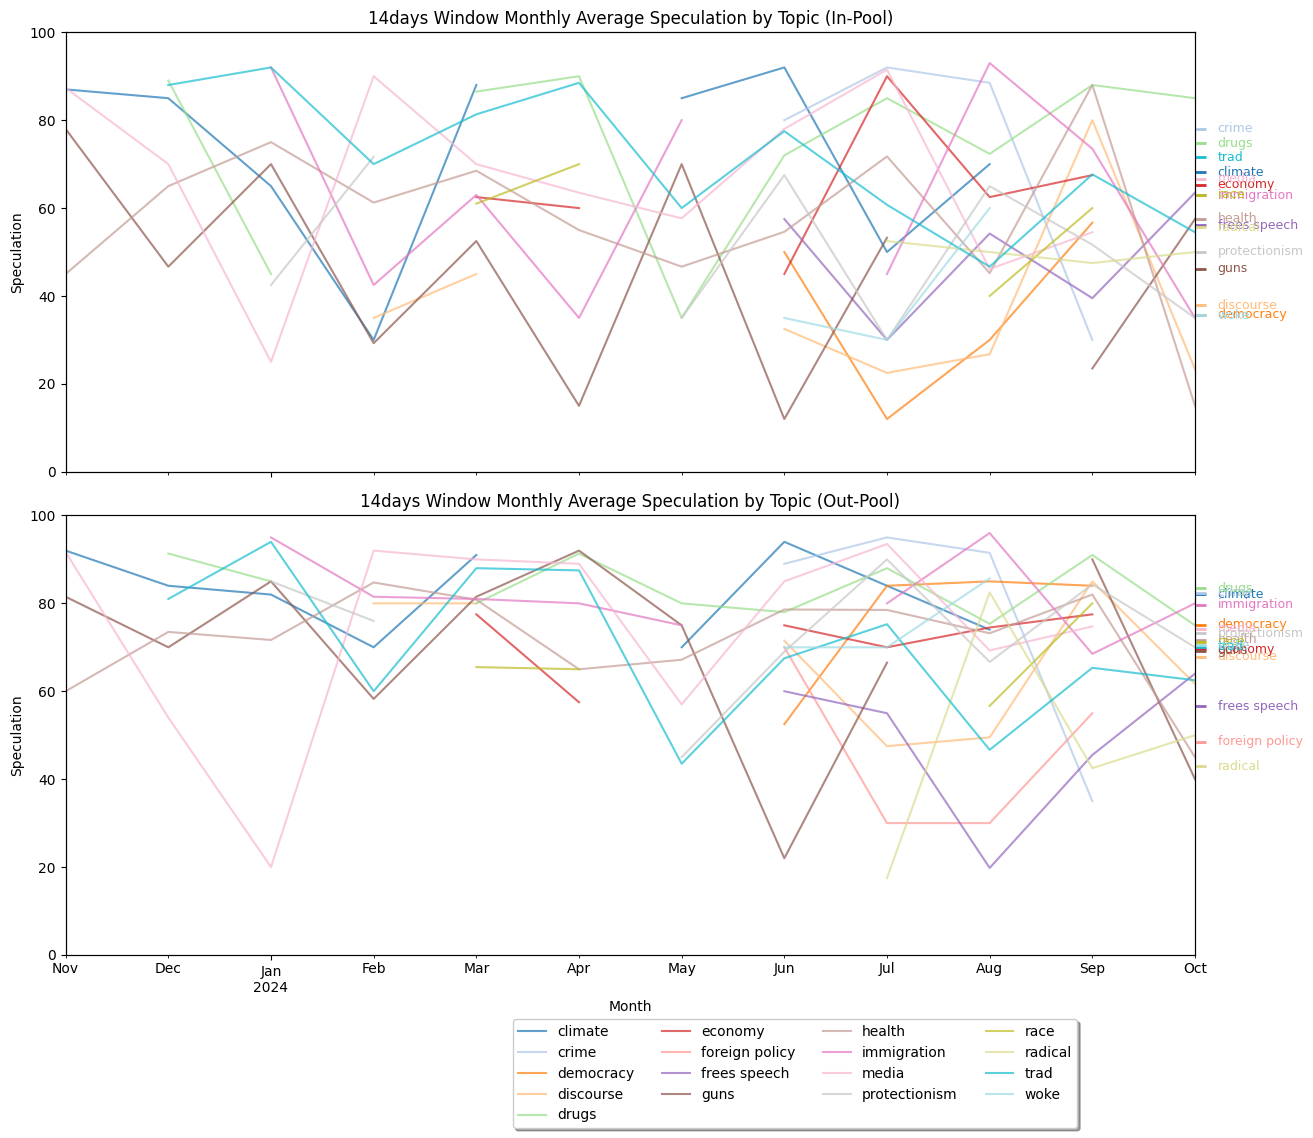

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

df = pd.read_csv("../generated_data/timebin_identification/14days_window/14days_alltopics_beliefs_scored.csv")
df["window_start"] = pd.to_datetime(df["window_start"])
df["month"] = df["window_start"].dt.to_period("M").dt.to_timestamp()

# Inpool specualtion by month
monthly_inpool = (
    df.groupby(["month", "Topic"])["Belief_inpool_Speculation"]
    .mean()
    .reset_index()
)
monthly_inpool_pivot = monthly_inpool.pivot(
    index="month", columns="Topic", values="Belief_inpool_Speculation"
)
all_months = pd.date_range(monthly_inpool_pivot.index.min(), monthly_inpool_pivot.index.max(), freq="MS")
monthly_inpool_pivot = monthly_inpool_pivot.reindex(all_months)

# Outpool specualtion by month
monthly_outpool = (
    df.groupby(["month", "Topic"])["Belief_outpool_Speculation"]
    .mean()
    .reset_index()
)
monthly_outpool_pivot = monthly_outpool.pivot(
    index="month", columns="Topic", values="Belief_outpool_Speculation"
)
monthly_outpool_pivot = monthly_outpool_pivot.reindex(all_months)

# Compute per-topic average across all months
topic_avg_inpool = monthly_inpool_pivot.mean()
topic_avg_outpool = monthly_outpool_pivot.mean()

# Plot
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)  

num_topics = monthly_inpool_pivot.shape[1]
colors = cm.get_cmap("tab20", num_topics).colors  

# Get topic names from the columns
topic_names = monthly_inpool_pivot.columns.tolist()

# --- In-Pool ---
monthly_inpool_pivot.plot(ax=axes[0], color=colors, alpha=0.7, legend=False)
axes[0].set_title("14days Window Monthly Average Speculation by Topic (In-Pool)")
axes[0].set_ylabel("Speculation")

ax2_in = axes[0].twinx()
ax2_in.set_ylim(axes[0].get_ylim())
ax2_in.set_yticks(topic_avg_inpool.values)
ax2_in.set_yticklabels([])  
ax2_in.yaxis.set_ticks_position('right')

# Color each tick individually and add topic names
for i, (tick, color, topic_name) in enumerate(zip(ax2_in.yaxis.get_major_ticks(), colors, topic_names)):
    tick.tick2line.set_markeredgecolor(color)
    tick.tick2line.set_markersize(8)
    tick.tick2line.set_markeredgewidth(2)
    
    # Add text label next to the tick
    ax2_in.text(1.02, topic_avg_inpool.values[i], topic_name, 
               color=color, transform=ax2_in.get_yaxis_transform(),
               va='center', ha='left', fontsize=9)

# --- Out-Pool ---
monthly_outpool_pivot.plot(ax=axes[1], color=colors, alpha=0.7, legend=False)
axes[1].set_title("14days Window Monthly Average Speculation by Topic (Out-Pool)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Speculation")

# Right y-axis for colored ticks only
ax2_out = axes[1].twinx()
ax2_out.set_ylim(axes[1].get_ylim())
ax2_out.set_yticks(topic_avg_outpool.values)
ax2_out.set_yticklabels([])
ax2_out.yaxis.set_ticks_position('right')

# Color each tick individually and add topic names
for i, (tick, color, topic_name) in enumerate(zip(ax2_out.yaxis.get_major_ticks(), colors, topic_names)):
    tick.tick2line.set_markeredgecolor(color)
    tick.tick2line.set_markersize(8)
    tick.tick2line.set_markeredgewidth(2)
    
    # Add text label next to the tick
    ax2_out.text(1.02, topic_avg_outpool.values[i], topic_name, 
                color=color, transform=ax2_out.get_yaxis_transform(),
                va='center', ha='left', fontsize=9)

# fixed y-axis scale to 0-100
axes[0].set_ylim(0, 100)
axes[1].set_ylim(0, 100)
ax2_in.set_ylim(0, 100)
ax2_out.set_ylim(0, 100)

# Shared legend at the bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0), 
           ncol=4, fancybox=True, shadow=True, fontsize=10)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])  
plt.subplots_adjust(right=0.75, bottom=0.15)
plt.show()

C:\Users\yuyue\AppData\Local\Temp\ipykernel_32812\3717482946.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["window_start"].dt.to_period("M").dt.to_timestamp()
C:\Users\yuyue\AppData\Local\Temp\ipykernel_32812\3717482946.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap("tab20", num_topics).colors


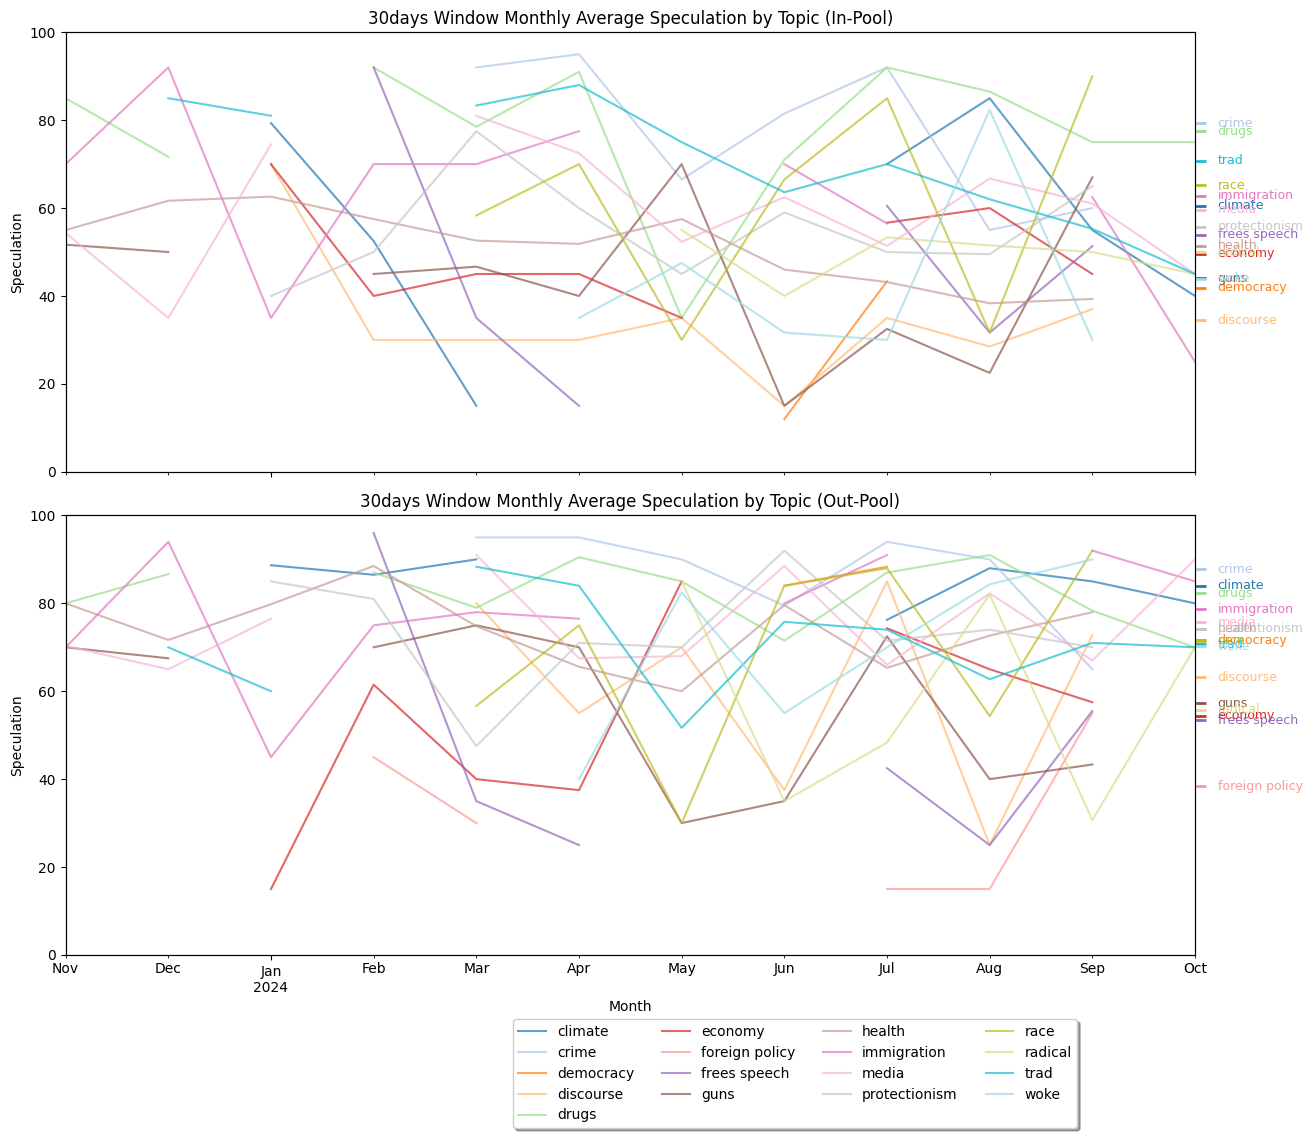

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

df = pd.read_csv("../generated_data/timebin_identification/30days_window/30days_alltopics_beliefs_scored.csv")
df["window_start"] = pd.to_datetime(df["window_start"])
df["month"] = df["window_start"].dt.to_period("M").dt.to_timestamp()

# Inpool specualtion by month
monthly_inpool = (
    df.groupby(["month", "Topic"])["Belief_inpool_Speculation"]
    .mean()
    .reset_index()
)
monthly_inpool_pivot = monthly_inpool.pivot(
    index="month", columns="Topic", values="Belief_inpool_Speculation"
)
all_months = pd.date_range(monthly_inpool_pivot.index.min(), monthly_inpool_pivot.index.max(), freq="MS")
monthly_inpool_pivot = monthly_inpool_pivot.reindex(all_months)

# Outpool specualtion by month
monthly_outpool = (
    df.groupby(["month", "Topic"])["Belief_outpool_Speculation"]
    .mean()
    .reset_index()
)
monthly_outpool_pivot = monthly_outpool.pivot(
    index="month", columns="Topic", values="Belief_outpool_Speculation"
)
monthly_outpool_pivot = monthly_outpool_pivot.reindex(all_months)

# Compute per-topic average across all months
topic_avg_inpool = monthly_inpool_pivot.mean()
topic_avg_outpool = monthly_outpool_pivot.mean()

# Plot
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)  

num_topics = monthly_inpool_pivot.shape[1]
colors = cm.get_cmap("tab20", num_topics).colors  

# Get topic names from the columns
topic_names = monthly_inpool_pivot.columns.tolist()

# --- In-Pool ---
monthly_inpool_pivot.plot(ax=axes[0], color=colors, alpha=0.7, legend=False)
axes[0].set_title("30days Window Monthly Average Speculation by Topic (In-Pool)")
axes[0].set_ylabel("Speculation")

ax2_in = axes[0].twinx()
ax2_in.set_ylim(axes[0].get_ylim())
ax2_in.set_yticks(topic_avg_inpool.values)
ax2_in.set_yticklabels([])  
ax2_in.yaxis.set_ticks_position('right')

# Color each tick individually and add topic names
for i, (tick, color, topic_name) in enumerate(zip(ax2_in.yaxis.get_major_ticks(), colors, topic_names)):
    tick.tick2line.set_markeredgecolor(color)
    tick.tick2line.set_markersize(8)
    tick.tick2line.set_markeredgewidth(2)
    
    # Add text label next to the tick
    ax2_in.text(1.02, topic_avg_inpool.values[i], topic_name, 
               color=color, transform=ax2_in.get_yaxis_transform(),
               va='center', ha='left', fontsize=9)

# --- Out-Pool ---
monthly_outpool_pivot.plot(ax=axes[1], color=colors, alpha=0.7, legend=False)
axes[1].set_title("30days Window Monthly Average Speculation by Topic (Out-Pool)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Speculation")

# Right y-axis for colored ticks only
ax2_out = axes[1].twinx()
ax2_out.set_ylim(axes[1].get_ylim())
ax2_out.set_yticks(topic_avg_outpool.values)
ax2_out.set_yticklabels([])
ax2_out.yaxis.set_ticks_position('right')

# Color each tick individually and add topic names
for i, (tick, color, topic_name) in enumerate(zip(ax2_out.yaxis.get_major_ticks(), colors, topic_names)):
    tick.tick2line.set_markeredgecolor(color)
    tick.tick2line.set_markersize(8)
    tick.tick2line.set_markeredgewidth(2)
    
    # Add text label next to the tick
    ax2_out.text(1.02, topic_avg_outpool.values[i], topic_name, 
                color=color, transform=ax2_out.get_yaxis_transform(),
                va='center', ha='left', fontsize=9)

# fixed y-axis scale to 0-100
axes[0].set_ylim(0, 100)
axes[1].set_ylim(0, 100)
ax2_in.set_ylim(0, 100)
ax2_out.set_ylim(0, 100)

# Shared legend at the bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0), 
           ncol=4, fancybox=True, shadow=True, fontsize=10)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])  
plt.subplots_adjust(right=0.75, bottom=0.15)
plt.show()

In [49]:
import pandas as pd
import numpy as np

df['is_empty_window'] = df['is_empty_window'].astype(bool)

# 1. Total and empty windows
total_windows = len(df)
empty_windows = df['is_empty_window'].sum()
coverage = 1 - (empty_windows / total_windows)

# 2. Mean & Std speculation (only for non-empty windows)
non_empty_df = df[~df['is_empty_window']]
mean_ispec = non_empty_df['Belief_inpool_Speculation'].mean()
std_ispec = non_empty_df['Belief_inpool_Speculation'].std()
mean_ospec = non_empty_df['Belief_outpool_Speculation'].mean()
std_ospec = non_empty_df['Belief_outpool_Speculation'].std()

# 3. Create summary table
summary = pd.DataFrame([{
    "Bin Size": "120 days",
    "Total Windows": total_windows,
    "Empty Windows": empty_windows,
    "Coverage (%)": f"{coverage*100:.1f}%",  
    "Mean Inpool Speculation (non-empty)": round(mean_ispec, 3),
    "Std Inpool Speculation (non-empty)": round(std_ispec, 3),
    "Mean Outpool Speculation (non-empty)": round(mean_ospec, 3),
    "Std Outpool Speculation (non-empty)": round(std_ospec, 3)
}])

summary


,Bin Size,Total Windows,Empty Windows,Coverage (%),Mean Inpool Speculation (non-empty),Std Inpool Speculation (non-empty),Mean Outpool Speculation (non-empty),Std Outpool Speculation (non-empty)
0,120 days,285,113,60.4%,56.44,26.459,70.322,23.39


In [50]:
summary.to_csv("../generated_data/timebin_identification/120days_window/120days_summary.csv")

In [52]:
summary_7d = pd.read_csv("../generated_data/timebin_identification/7days_window/7days_summary.csv")
summary_14d = pd.read_csv("../generated_data/timebin_identification/14days_window/14days_summary.csv")
summary_21d = pd.read_csv("../generated_data/timebin_identification/21days_window/21days_summary.csv")
summary_30d = pd.read_csv("../generated_data/timebin_identification/30days_window/30days_summary.csv")
summary_60d = pd.read_csv("../generated_data/timebin_identification/60days_window/60days_summary.csv")
summary_90d = pd.read_csv("../generated_data/timebin_identification/90days_window/90days_summary.csv")
summary_120d = pd.read_csv("../generated_data/timebin_identification/120days_window/120days_summary.csv")
final_summary = pd.concat([summary_7d, summary_14d, summary_21d, summary_30d, summary_60d, summary_90d, summary_120d], ignore_index=True).drop(columns=["Unnamed: 0"])
final_summary


,Bin Size,Total Windows,Empty Windows,Coverage (%),Mean Inpool Speculation (non-empty),Std Inpool Speculation (non-empty),Mean Outpool Speculation (non-empty),Std Outpool Speculation (non-empty)
0,7 days,620,364,41.3%,58.714,25.570,70.079,22.245
1,14 days,620,340,45.2%,58.722,26.121,71.039,21.576
2,21 days,617,321,48.0%,58.042,26.089,69.565,22.312
3,30 days,618,302,51.1%,57.010,26.289,69.933,23.321
4,60 days,601,268,55.4%,56.273,27.723,69.562,23.406
5,90 days,401,171,57.4%,54.376,27.895,67.271,24.042
6,120 days,285,113,60.4%,56.440,26.459,70.322,23.390


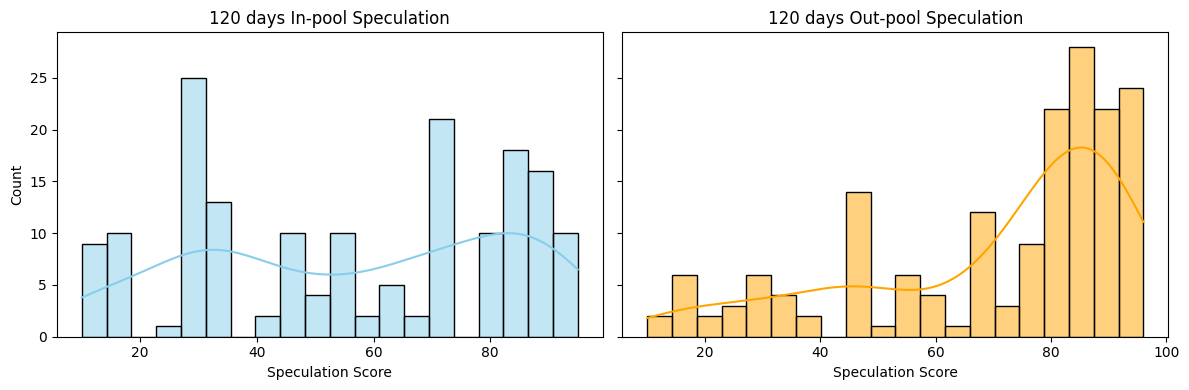

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

non_empty_df = df[~df['is_empty_window']]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.histplot(non_empty_df['Belief_inpool_Speculation'], kde=True, bins=20, color='skyblue', ax=axes[0])
axes[0].set_title("120 days In-pool Speculation")

sns.histplot(non_empty_df['Belief_outpool_Speculation'], kde=True, bins=20, color='orange', ax=axes[1])
axes[1].set_title("120 days Out-pool Speculation")

for ax in axes:
    ax.set_xlabel("Speculation Score")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.savefig(os.path.join("../generated_viz/timebin_identification", "speculation_distribution_120d.png"), dpi=300)
plt.show()


C:\Users\yuyue\AppData\Local\Temp\ipykernel_24200\4204031635.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['month'] = df['window_start'].dt.to_period('M').dt.to_timestamp()


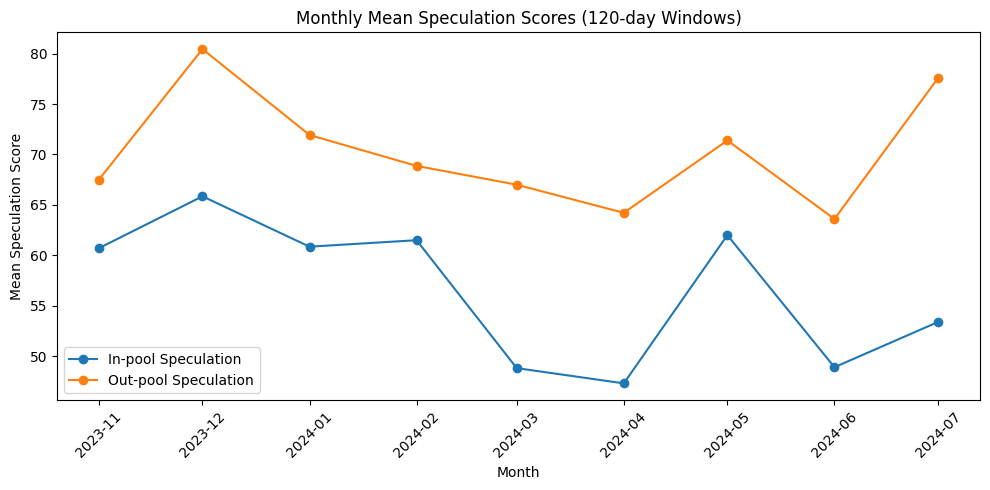

In [54]:
df['window_start'] = pd.to_datetime(df['window_start'])
df['month'] = df['window_start'].dt.to_period('M').dt.to_timestamp()

non_empty_df = df[~df['is_empty_window']]

monthly_spec = non_empty_df.groupby('month').agg(
    mean_inpool=('Belief_inpool_Speculation', 'mean'),
    mean_outpool=('Belief_outpool_Speculation', 'mean')
).reset_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_spec['month'], monthly_spec['mean_inpool'], marker='o', label='In-pool Speculation')
plt.plot(monthly_spec['month'], monthly_spec['mean_outpool'], marker='o', label='Out-pool Speculation')

plt.title("Monthly Mean Speculation Scores (120-day Windows)")
plt.xlabel("Month")
plt.ylabel("Mean Speculation Score")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join("../generated_viz/timebin_identification", "speculation_per_months_120d.png"), dpi=300)
plt.show()

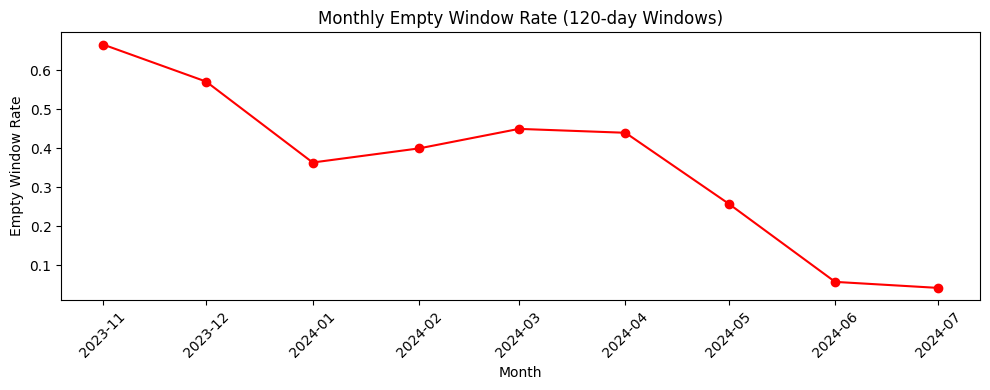

In [55]:
monthly_empty = df.groupby('month').agg(
    total_windows=('id', 'count'),
    empty_windows=('is_empty_window', 'sum')
).reset_index()

monthly_empty['empty_rate'] = monthly_empty['empty_windows'] / monthly_empty['total_windows']

plt.figure(figsize=(10, 4))
plt.plot(monthly_empty['month'], monthly_empty['empty_rate'], marker='o', color='red')
plt.title("Monthly Empty Window Rate (120-day Windows)")
plt.xlabel("Month")
plt.ylabel("Empty Window Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join("../generated_viz/timebin_identification", "empty_window_per_months_120d.png"), dpi=300)
plt.show()
